# 🤖 03 — Modeling
### FraudShield | IEEE-CIS Fraud Detection | Phase 3 of the project tracker

**Goal:** train and compare models rigorously on imbalanced, time-ordered data, then ship a calibrated model artifact for the API.

| Tracker | Section | What happens |
|---|---|---|
| 3.1 | 3 | Logistic Regression baseline (class weights) |
| 3.2 | 4 | XGBoost (`scale_pos_weight`, early stopping on validation) |
| 3.3 | 5 | LightGBM (same setup, compare speed + quality) |
| 3.4 | 6 | Optuna tuning of the better GBDT, **time-aware folds inside train only** |
| 3.5 – 3.6 | 4 – 7 | PR-AUC, ROC-AUC, recall @ 1% FPR, PR / ROC curves, cold-start slices |
| 3.7 | 8 | Calibration (Platt vs isotonic), honest check on later half of validation |
| 3.8 | 9 | Final evaluation on the untouched holdout, **run once** |
| 3.9 | 10 | Save model + calibrator + metadata to `ml/artifacts/` |

### Rules this notebook enforces
1. **Holdout is physically not loaded** until section 9 (the loader filters it out at read time).
2. **No accuracy.** Headline metrics: PR-AUC, ROC-AUC, recall at a fixed false-positive rate.
3. **Tuning never sees validation.** Optuna uses expanding-window folds *inside train*. Validation is for early stopping, model choice and calibration.
4. **Thresholds come from validation**, then get applied unchanged to the holdout.
5. Model / metric code lives in `ml/training/train.py` and `evaluate.py` so notebook, CLI and (later) the API stay consistent.

**Prerequisites:** `data/processed/features.parquet`, `ml/artifacts/feature_schema.json` (from Phase 2).
**Extra libs:** `xgboost lightgbm optuna scikit-learn pyarrow`.
**Memory:** ~4-6 GB RAM. Set env var `FRAUD_FAST=1` for a 2-minute smoke run on a subsample.

## 0. Setup

In [7]:
import gc
import json
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})

# ---- Paths (override with environment variables if your layout differs) ----
PROCESSED_DIR = Path(os.environ.get("FRAUD_PROCESSED_DIR", "../../data/processed"))
ARTIFACTS_DIR = Path(os.environ.get("FRAUD_ARTIFACTS_DIR", "../artifacts"))
TRAINING_DIR  = Path(os.environ.get("FRAUD_TRAINING_DIR", "../training"))
FIG_DIR       = Path(os.environ.get("FRAUD_FIG_DIR", "../../docs/model_figures"))
SAVE_FIGS     = True
COLORS = {"legit": "#3B82F6", "fraud": "#EF4444", "neutral": "#94A3B8", "good": "#10B981"}

# ---- Run configuration ----
FAST          = os.environ.get("FRAUD_FAST", "0") == "1"    # smoke-test mode (tiny models, 2 trials)
FPR_TARGET    = 0.01                                        # "recall at 1% false-positive rate"
N_TRIALS      = 2 if FAST else 15                           # Optuna trials (each = 2 fits on train folds)
TIMEOUT_MIN   = 45                                          # hard stop for tuning
FAST_OVR      = {"n_estimators": 60} if FAST else {}        # shrink models in smoke-test mode
TUNE_OVR      = {"learning_rate": 0.1, "n_estimators": 40 if FAST else 600}   # faster models while tuning
FORCE_HOLDOUT_RERUN = False                                 # leave False: the holdout is for ONE evaluation

sys.path.insert(0, str(TRAINING_DIR.resolve()))
import evaluate as ev
import train as T


def save_fig(name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


FEATURES_PATH = PROCESSED_DIR / "features.parquet"
if not FEATURES_PATH.exists():
    FEATURES_PATH = PROCESSED_DIR / "features.pkl"      # Phase 2 fallback when pyarrow was missing
print("Features file :", FEATURES_PATH.resolve())
print("Artifacts dir :", ARTIFACTS_DIR.resolve())
print("FAST mode     :", FAST)

Features file : C:\VS CODE\PROJECTS\FraudShield AI\data\processed\features.parquet
Artifacts dir : C:\VS CODE\PROJECTS\FraudShield AI\ml\artifacts
FAST mode     : False


## 1. Load train + validation only  *(rule 1: holdout stays sealed)*

`T.load_features(..., splits=("train", "validation"))` filters at read time, so the holdout rows never enter this notebook's memory. Rows are sorted by `TransactionDT`, which matters for the time-aware tuning folds later.

In [8]:
schema = json.load(open(ARTIFACTS_DIR / "feature_schema.json"))
FEATURES = schema["feature_order"]
print(f"Schema: {len(FEATURES)} features, dtype {schema['dtype']}")

meta, X = T.load_features(FEATURES_PATH, FEATURES, splits=("train", "validation"))
is_tr = (meta["split"] == "train").to_numpy()

X_tr, y_tr = X.loc[is_tr].reset_index(drop=True), meta.loc[is_tr, "isFraud"].to_numpy()
X_va, y_va = X.loc[~is_tr].reset_index(drop=True), meta.loc[~is_tr, "isFraud"].to_numpy()
meta_va = meta.loc[~is_tr].reset_index(drop=True)
del X
gc.collect()

# Safety checks
assert set(meta["split"].unique()) == {"train", "validation"}, "holdout leaked into this notebook!"
assert meta.loc[is_tr, "TransactionDT"].max() < meta.loc[~is_tr, "TransactionDT"].min(), "train/validation overlap in time"
assert not np.isinf(X_tr.to_numpy()).any(), "inf values in features"

POS_RATIO = T.pos_weight_ratio(y_tr)      # negatives per positive -> scale_pos_weight
summary = pd.DataFrame({
    "rows": [len(y_tr), len(y_va)],
    "fraud": [int(y_tr.sum()), int(y_va.sum())],
    "fraud_rate": [y_tr.mean(), y_va.mean()],
    "memory_MB": [X_tr.memory_usage(deep=True).sum() / 1e6, X_va.memory_usage(deep=True).sum() / 1e6],
}, index=["train", "validation"])
display(summary)
print(f"scale_pos_weight (neg/pos) = {POS_RATIO:.1f}")

# Features that never vary in train are dead weight (trees ignore them, but they are worth knowing about)
nun = X_tr.nunique(dropna=True)
dead = nun[nun <= 1].index.tolist()
print(f"Constant / empty features in train ({len(dead)}): {dead[:20]}")

Schema: 434 features, dtype float32


,rows,fraud,fraud_rate,memory_MB
train,413378,14538,0.0352,717.6243
validation,88581,3042,0.0343,153.7767


scale_pos_weight (neg/pos) = 27.4
Constant / empty features in train (2): ['V107', 'new_addr_flag']


## 2. Metrics sanity check

Quick proof that the metric helpers behave: a scorer that knows nothing (constant score) must land at **PR-AUC = base fraud rate** and **ROC-AUC = 0.5**. Anything we build has to beat *that*, not "96.5% accuracy".

In [9]:
dummy = ev.evaluate(y_va, np.zeros(len(y_va)), FPR_TARGET)
print(f"Constant scorer -> PR-AUC {dummy['pr_auc']:.4f} (base rate {y_va.mean():.4f}) | ROC-AUC {dummy['roc_auc']:.3f}")

# Registry for every model scored on validation
results, val_scores = {}, {}

def log_result(name, scores, fit_s=np.nan, n_trees=np.nan):
    m = ev.evaluate(y_va, scores, FPR_TARGET)
    results[name] = {**m, "fit_s": fit_s, "n_trees": n_trees}
    val_scores[name] = np.asarray(scores)
    return m

def results_table():
    cols = ["pr_auc", "roc_auc", "recall_at_fpr", "precision_at_fpr", "fit_s", "n_trees"]
    return pd.DataFrame(results).T[cols]

Constant scorer -> PR-AUC 0.0343 (base rate 0.0343) | ROC-AUC 0.500


## 3. Baseline: Logistic Regression  *(tracker 3.1)*

Median imputation, quantile-to-normal scaling (robust to the heavy tails in `C`, `D`, `V` columns), class-weighted LR. Trees get raw `NaN`s; a linear model cannot, so this is deliberately the "boring but fair" reference. Expect it to be clearly beaten.

> Missing-value info is mostly lost here (imputed). That is part of why trees should win.

In [10]:
t0 = time.time()
base = T.make_baseline(max_iter=100 if FAST else 300)
base.fit(X_tr, y_tr)
p_base = base.predict_proba(X_va)[:, 1]
m = log_result("logreg", p_base, time.time() - t0)
print(f"LogReg done in {time.time() - t0:,.0f}s | PR-AUC {m['pr_auc']:.4f} | ROC-AUC {m['roc_auc']:.4f} | "
      f"recall@{FPR_TARGET:.0%}FPR {m['recall_at_fpr']:.3f}")

LogReg done in 66s | PR-AUC 0.4182 | ROC-AUC 0.8621 | recall@1%FPR 0.339


## 4. XGBoost  *(tracker 3.2)*

`tree_method="hist"`, `scale_pos_weight = neg/pos`, early stopping on **validation PR-AUC** (`aucpr`). `NaN` is handled natively. Early stopping on validation is legitimate here (validation exists for this); the holdout is not involved.

In [11]:
xgb_m = T.make_model("xgboost", FAST_OVR, POS_RATIO)
secs = T.fit_model("xgboost", xgb_m, X_tr, y_tr, X_va, y_va)
n_trees = T.best_iteration("xgboost", xgb_m)
m = log_result("xgboost", T.predict_scores(xgb_m, X_va), secs, n_trees)
print(f"XGBoost: {n_trees} trees, {secs:,.0f}s | PR-AUC {m['pr_auc']:.4f} | ROC-AUC {m['roc_auc']:.4f} | "
      f"recall@{FPR_TARGET:.0%}FPR {m['recall_at_fpr']:.3f}")

XGBoost: 2998 trees, 1,017s | PR-AUC 0.6092 | ROC-AUC 0.9174 | recall@1%FPR 0.538


## 5. LightGBM  *(tracker 3.3)*

Same idea, different tree-growth strategy (leaf-wise). Compare quality **and** fit time.

In [12]:
lgb_m = T.make_model("lightgbm", FAST_OVR, POS_RATIO)
secs = T.fit_model("lightgbm", lgb_m, X_tr, y_tr, X_va, y_va)
n_trees = T.best_iteration("lightgbm", lgb_m)
m = log_result("lightgbm", T.predict_scores(lgb_m, X_va), secs, n_trees)
print(f"LightGBM: {n_trees} trees, {secs:,.0f}s | PR-AUC {m['pr_auc']:.4f} | ROC-AUC {m['roc_auc']:.4f} | "
      f"recall@{FPR_TARGET:.0%}FPR {m['recall_at_fpr']:.3f}")

display(results_table())
BEST_NAME = max(["xgboost", "lightgbm"], key=lambda k: results[k]["pr_auc"])
print(f"-> Tuning candidate (higher validation PR-AUC): {BEST_NAME}")

LightGBM: 2988 trees, 249s | PR-AUC 0.6457 | ROC-AUC 0.9260 | recall@1%FPR 0.571


,pr_auc,roc_auc,recall_at_fpr,precision_at_fpr,fit_s,n_trees
logreg,0.4182,0.8621,0.3393,0.5472,65.9401,NaN
xgboost,0.6092,0.9174,0.5378,0.6576,"1,017.4860","2,998.0000"
lightgbm,0.6457,0.9260,0.5710,0.6709,249.2293,"2,988.0000"


-> Tuning candidate (higher validation PR-AUC): lightgbm


## 6. Tune the better model with Optuna  *(tracker 3.4)*

**Time-aware, and validation-free.** Two expanding-window folds *inside train*:

```
fold 1: fit on first 50% of train  -> score on next 25%
fold 2: fit on first 75% of train  -> score on last 25%
```
Objective = mean PR-AUC across folds. A faster learning rate (0.1) and fewer trees keep each trial cheap; the winning parameters are then refit at learning rate 0.05 with early stopping on validation.

`spw_mult` lets Optuna soften `scale_pos_weight` (1.0 = full balance). Full balancing often hurts ranking slightly and wrecks probability calibration, which Section 8 repairs anyway.

> ⏱ Each trial fits 2 models. Expect roughly 3 to 8 minutes per trial on a laptop CPU. `N_TRIALS` / `TIMEOUT_MIN` in the setup cell cap the total.

In [13]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TR = len(X_tr)
FOLDS = [(0.50, 0.75), (0.75, 1.00)]


def suggest(trial, name):
    if name == "xgboost":
        return dict(
            max_depth=trial.suggest_int("max_depth", 4, 10),
            min_child_weight=trial.suggest_float("min_child_weight", 1, 20, log=True),
            subsample=trial.suggest_float("subsample", 0.6, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 0.9),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
            gamma=trial.suggest_float("gamma", 0.0, 5.0),
            spw_mult=trial.suggest_float("spw_mult", 0.05, 1.0, log=True),
        )
    return dict(
        num_leaves=trial.suggest_int("num_leaves", 31, 255, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 300, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 0.9),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        spw_mult=trial.suggest_float("spw_mult", 0.05, 1.0, log=True),
    )


def objective(trial):
    params = {**TUNE_OVR, **suggest(trial, BEST_NAME)}
    scores = []
    for a, b in FOLDS:
        ia, ib = int(a * N_TR), int(b * N_TR)
        Xa, ya, Xb, yb = X_tr.iloc[:ia], y_tr[:ia], X_tr.iloc[ia:ib], y_tr[ia:ib]
        model = T.make_model(BEST_NAME, params, T.pos_weight_ratio(ya), early_stopping_rounds=50)
        T.fit_model(BEST_NAME, model, Xa, ya, Xb, yb, early_stopping_rounds=50)
        scores.append(average_precision_score(yb, T.predict_scores(model, Xb)))
    trial.set_user_attr("fold_scores", [round(s, 4) for s in scores])
    return float(np.mean(scores))


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_MIN * 60, show_progress_bar=False)
done = [t for t in study.trials if t.state.name == "COMPLETE"]
print(f"Tuning: {len(done)} completed trials in {(time.time() - t0) / 60:,.1f} min")

if done:
    trials_df = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs")).sort_values("value", ascending=False)
    display(trials_df.head(8))
    print("Best params:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in study.best_params.items()})
else:
    print("No trial finished (timeout too small?). The untuned model will be used.")

Tuning: 15 completed trials in 17.9 min


,number,value,params_colsample_bytree,params_min_child_samples,params_num_leaves,params_reg_alpha,params_reg_lambda,params_spw_mult,params_subsample,user_attrs_fold_scores
12,12,0.6062,0.6285,25,200,0.0021,0.2665,0.1485,0.7415,"[0.6215, 0.591]"
14,14,0.6023,0.6313,41,151,0.0024,0.0934,0.1055,0.8125,"[0.6191, 0.5856]"
5,5,0.5979,0.7105,45,170,0.0031,0.4247,0.2204,0.6391,"[0.6071, 0.5886]"
10,10,0.5952,0.8671,34,114,0.0107,0.7720,0.2169,0.7564,"[0.6108, 0.5795]"
11,11,0.5946,0.7953,29,181,0.0093,0.6013,0.2221,0.6137,"[0.6079, 0.5812]"
1,1,0.5894,0.3124,101,192,2.1368,38.6961,0.0945,0.8832,"[0.5959, 0.5828]"
13,13,0.5887,0.5400,28,102,0.0020,0.1987,0.2996,0.7068,"[0.6045, 0.5729]"
4,4,0.5874,0.4023,22,107,6.2451,0.0174,0.9022,0.8430,"[0.5939, 0.5808]"


Best params: {'num_leaves': 200, 'min_child_samples': 25, 'subsample': 0.7415, 'colsample_bytree': 0.6285, 'reg_lambda': 0.2665, 'reg_alpha': 0.0021, 'spw_mult': 0.1485}


In [14]:
# Refit the winning parameters at the normal learning rate, early-stopping on validation.
TUNED = f"{BEST_NAME}_tuned"
candidates = {BEST_NAME: ({}, xgb_m if BEST_NAME == "xgboost" else lgb_m)}

if done:
    tuned_params = dict(study.best_params)
    tuned_m = T.make_model(BEST_NAME, {**FAST_OVR, **tuned_params}, POS_RATIO)
    secs = T.fit_model(BEST_NAME, tuned_m, X_tr, y_tr, X_va, y_va)
    n_trees = T.best_iteration(BEST_NAME, tuned_m)
    m = log_result(TUNED, T.predict_scores(tuned_m, X_va), secs, n_trees)
    candidates[TUNED] = (tuned_params, tuned_m)

display(results_table())

# Keep whichever scored higher on validation PR-AUC (tuning is not guaranteed to win)
FINAL_NAME = max(candidates, key=lambda k: results[k]["pr_auc"])
FINAL_PARAMS, final_model = candidates[FINAL_NAME]
FINAL_TYPE = BEST_NAME
FINAL_TREES = int(results[FINAL_NAME]["n_trees"])
print(f"-> Final model: {FINAL_NAME} ({FINAL_TREES} trees)")

,pr_auc,roc_auc,recall_at_fpr,precision_at_fpr,fit_s,n_trees
logreg,0.4182,0.8621,0.3393,0.5472,65.9401,NaN
xgboost,0.6092,0.9174,0.5378,0.6576,"1,017.4860","2,998.0000"
lightgbm,0.6457,0.9260,0.5710,0.6709,249.2293,"2,988.0000"
lightgbm_tuned,0.6563,0.9300,0.5776,0.6727,834.7843,"2,316.0000"


-> Final model: lightgbm_tuned (2316 trees)


## 7. Evaluate on validation: curves, slices, importance  *(tracker 3.5, 3.6)*

Operating point marked on the ROC plot: **1% false-positive rate**, i.e. at most 1 in 100 legitimate customers gets flagged.

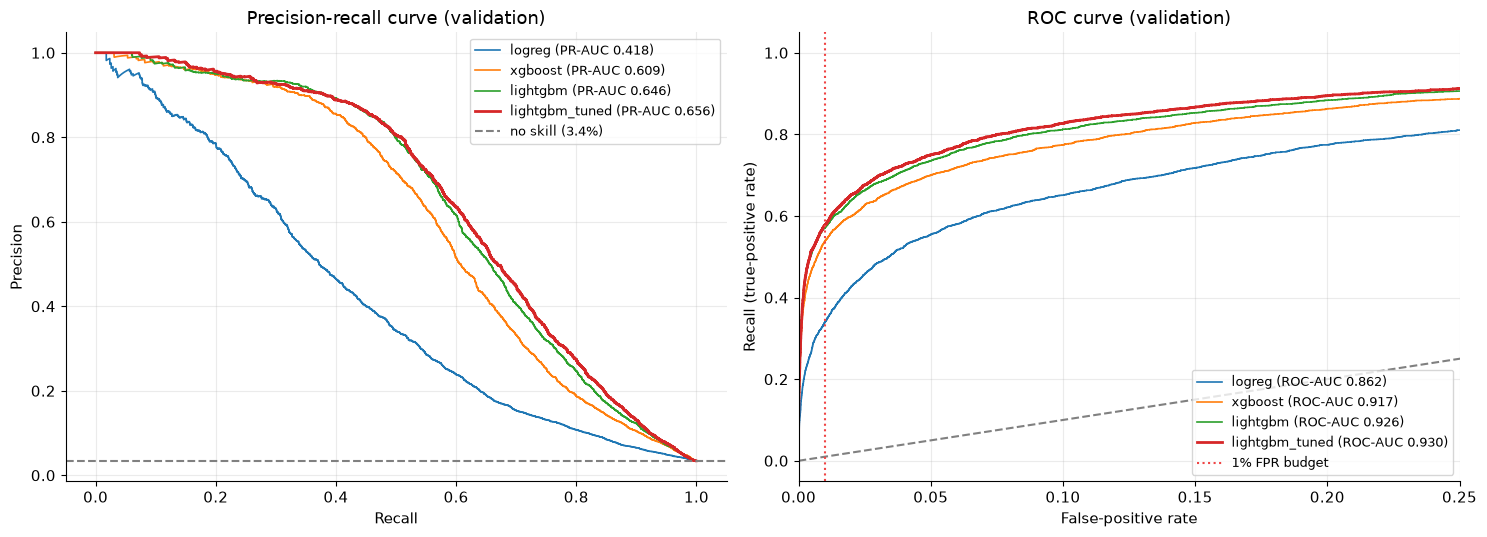

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for name, s in val_scores.items():
    prec, rec, _ = precision_recall_curve(y_va, s)
    axes[0].plot(rec, prec, lw=2 if name == FINAL_NAME else 1.2, label=f"{name} (PR-AUC {results[name]['pr_auc']:.3f})")
    fpr, tpr, _ = roc_curve(y_va, s)
    axes[1].plot(fpr, tpr, lw=2 if name == FINAL_NAME else 1.2, label=f"{name} (ROC-AUC {results[name]['roc_auc']:.3f})")
axes[0].axhline(y_va.mean(), ls="--", color="gray", label=f"no skill ({y_va.mean():.1%})")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (validation)")
axes[0].legend(loc="upper right", fontsize=9)
axes[1].plot([0, 1], [0, 1], ls="--", color="gray")
axes[1].axvline(FPR_TARGET, ls=":", color=COLORS["fraud"], label=f"{FPR_TARGET:.0%} FPR budget")
axes[1].set(xlabel="False-positive rate", ylabel="Recall (true-positive rate)", title="ROC curve (validation)", xlim=(0, 0.25))
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_fig("01_pr_roc_validation")
plt.show()

In [16]:
# Cold-start matters: a hand-typed demo transaction has no card history and no identity.
raw_va = val_scores[FINAL_NAME]
masks = {"all validation": np.ones(len(y_va), dtype=bool)}
if "b_hist_count" in X_va:
    masks["cold start (card has no history)"] = (X_va["b_hist_count"] == 0).to_numpy()
    masks["warm (card has history)"] = (X_va["b_hist_count"] > 0).to_numpy()
if "has_identity" in X_va:
    masks["no identity data"] = (X_va["has_identity"] == 0).to_numpy()
    masks["has identity data"] = (X_va["has_identity"] == 1).to_numpy()
if "ProductCD" in X_va:
    for code_, label in enumerate(["ProductCD code 0", "ProductCD code 1", "ProductCD code 2", "ProductCD code 3", "ProductCD code 4"]):
        if (X_va["ProductCD"] == code_).sum() > 500:
            masks[label] = (X_va["ProductCD"] == code_).to_numpy()
slice_df = ev.slice_report(y_va, raw_va, masks, FPR_TARGET)
display(slice_df)
print("Read: if cold-start recall is far below warm recall, the manual demo form will look weaker than the live feed.")

,n,fraud_rate,pr_auc,roc_auc,recall_at_fpr,precision_at_fpr
all validation,"88,581.0000",0.0343,0.6563,0.9300,0.5776,0.6727
cold start (card has no history),"27,411.0000",0.0312,0.6008,0.8918,0.5380,0.6354
warm (card has history),"61,170.0000",0.0358,0.6812,0.9441,0.5940,0.6880
no identity data,"72,927.0000",0.0209,0.4898,0.9064,0.4600,0.4961
has identity data,"15,654.0000",0.0970,0.8133,0.9455,0.6265,0.8709


Read: if cold-start recall is far below warm recall, the manual demo form will look weaker than the live feed.


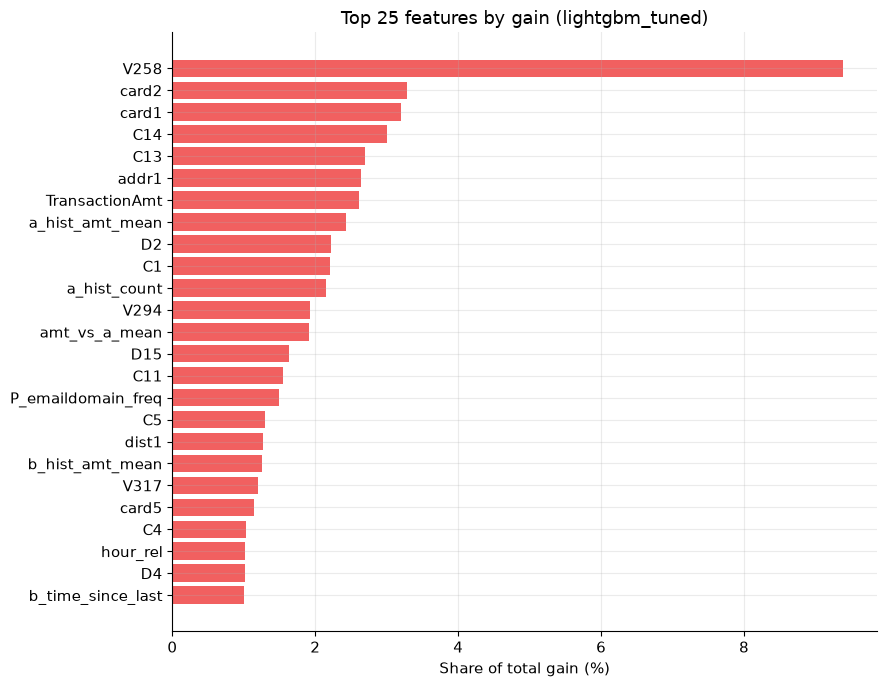

Top feature takes 9.4% of total gain; top 10 take 33.7%.
Red flag check: one feature with a huge share (say > 40%) usually means leakage or an ID-like column. Look at it before trusting the score.
Rank of engineered card-history features: {'a_hist_amt_mean': 8, 'a_hist_count': 11, 'amt_vs_a_mean': 13, 'b_hist_amt_mean': 19, 'b_time_since_last': 25, 'amt_vs_b_mean': 34, 'a_txn_count_24h': 35, 'b_amt_sum_24h': 64}
Never-used features (zero gain): 8 of 434


In [17]:
imp = T.feature_importance(FINAL_TYPE, final_model, FEATURES)
top = imp.head(25)
share = imp / imp.sum()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index[::-1], (share.head(25) * 100).values[::-1], color=COLORS["fraud"], alpha=0.85)
ax.set_xlabel("Share of total gain (%)")
ax.set_title(f"Top 25 features by gain ({FINAL_NAME})")
plt.tight_layout()
save_fig("02_feature_importance")
plt.show()

print(f"Top feature takes {share.iloc[0]:.1%} of total gain; top 10 take {share.head(10).sum():.1%}.")
print("Red flag check: one feature with a huge share (say > 40%) usually means leakage or an ID-like column. Look at it before trusting the score.")
new_feats = [c for c in imp.index if c.startswith(("b_", "a_", "new_", "amt_vs"))]
print("Rank of engineered card-history features:", {c: int(imp.index.get_loc(c)) + 1 for c in new_feats[:8]})
print("Never-used features (zero gain):", int((imp == 0).sum()), "of", len(imp))

### 7b. Drift sensitivity: `id_31` (browser)

Phase 2 printed that **45% of holdout `id_31` values were never seen in train**, versus 0.08% in validation. Validation therefore cannot warn us about it. The cheap fix: *simulate* it. Set the frequency-encoded `id_31` features to the "unseen" value (0.0) on 45% of validation rows and see how much PR-AUC drops. A big drop means the model leans on a feature that will rot in production (browser versions change constantly).

In [18]:
vol_cols = [c for c in FEATURES if "id_31" in c]
print("Volatile columns matched:", vol_cols)
if vol_cols:
    rng = np.random.default_rng(42)
    X_sim = X_va.copy()
    hit = rng.random(len(X_sim)) < 0.45
    X_sim.loc[hit, vol_cols] = 0.0
    p_sim = T.predict_scores(final_model, X_sim)
    base_ap = results[FINAL_NAME]["pr_auc"]
    sim_ap = average_precision_score(y_va, p_sim)
    print(f"PR-AUC clean {base_ap:.4f} -> with 45% of id_31 'unseen' {sim_ap:.4f}  (change {sim_ap - base_ap:+.4f})")
    del X_sim
else:
    print("No id_31 columns found in the feature schema; skipping.")

Volatile columns matched: ['id_31_freq']
PR-AUC clean 0.6563 -> with 45% of id_31 'unseen' 0.6472  (change -0.0090)


## 8. Calibrate probabilities  *(tracker 3.7)*

`scale_pos_weight` pushes raw scores far above the true fraud rate, so a raw score of 0.9 does **not** mean "90% chance of fraud". The API's 0 to 100 risk score must mean something, so we calibrate.

**Honest test:** fit each calibrator on the *earlier half* of validation, judge it on the *later half* (never seen by the calibrator). Brier score and ECE (expected calibration error) lower = better. The winner is then refit on all of validation for the saved artifact.

> Isotonic output has plateaus (ties), which can nudge PR-AUC slightly. Ranking metrics in this notebook are therefore always computed on the **raw** score; calibrated values are used for the risk score and cost model.

,brier,log_loss,ece,mean_pred,observed_rate,pr_auc
method,,,,,,
none,0.0219,0.1358,0.0184,0.0143,0.0327,0.5672
sigmoid,0.0199,0.0824,0.0020,0.0311,0.0327,0.5672
isotonic,0.0199,0.0836,0.0029,0.0313,0.0327,0.5478


-> Calibration method: sigmoid (lowest Brier on the held-out half of validation)


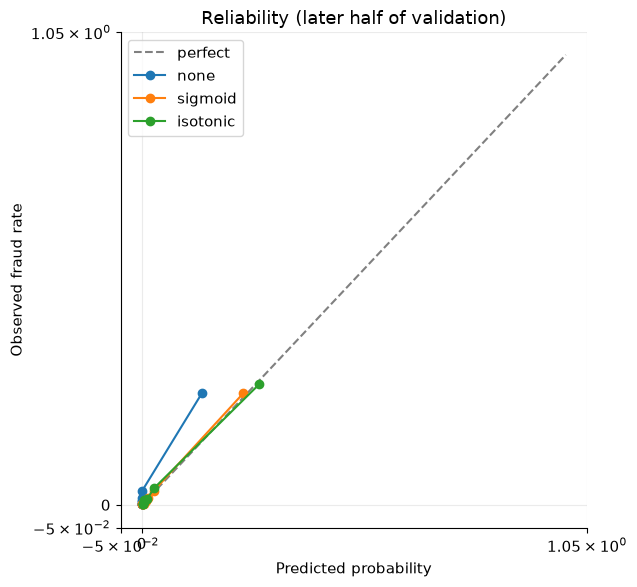

Calibrated mean score 0.0344 vs observed fraud rate 0.0343


In [19]:
half = len(y_va) // 2
fit_part, test_part = slice(0, half), slice(half, None)

rows, cal_probs = [], {}
for method in ["none", "sigmoid", "isotonic"]:
    c = T.Calibrator.fit(method, raw_va[fit_part], y_va[fit_part])
    p = c.predict(raw_va[test_part])
    cal_probs[method] = p
    rows.append({"method": method, **ev.calibration_report(y_va[test_part], p),
                 "pr_auc": average_precision_score(y_va[test_part], p)})
cal_table = pd.DataFrame(rows).set_index("method")
display(cal_table)

BEST_CAL = cal_table["brier"].idxmin()
print(f"-> Calibration method: {BEST_CAL} (lowest Brier on the held-out half of validation)")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="perfect")
for method, p in cal_probs.items():
    t = ev.reliability_table(y_va[test_part], p, 10)
    ax.plot(t["mean_pred"], t["frac_pos"], marker="o", label=method)
ax.set(xlabel="Predicted probability", ylabel="Observed fraud rate", title="Reliability (later half of validation)",
       xscale="symlog", yscale="symlog")
ax.legend()
plt.tight_layout()
save_fig("03_calibration")
plt.show()

# Final calibrator: refit on ALL of validation (the model never trained on it)
calibrator = T.Calibrator.fit(BEST_CAL, raw_va, y_va)
cal_va = calibrator.predict(raw_va)
print(f"Calibrated mean score {cal_va.mean():.4f} vs observed fraud rate {y_va.mean():.4f}")

## 9. Final evaluation on the untouched holdout  *(tracker 3.8)*  ⚠️ run once

Everything is frozen now: features, model, tuning, calibrator, and the **1%-FPR threshold, which is taken from validation** and applied unchanged. Two recall numbers are reported:

- **oracle** recall @ 1% FPR: best achievable on the holdout itself (the usual leaderboard-style number)
- **validation-threshold** recall: what you actually get when the threshold was chosen *before* seeing the holdout (the honest, production-like number)

A guard file (`ml/artifacts/holdout_result.json`) stops accidental re-runs: looking at the holdout repeatedly and adjusting turns it into a second validation set.

In [20]:
RESULT_PATH = ARTIFACTS_DIR / "holdout_result.json"
if RESULT_PATH.exists() and not FORCE_HOLDOUT_RERUN:
    raise RuntimeError(f"{RESULT_PATH} exists: the holdout was already evaluated. "
                       "Re-running it invalidates the result. Set FORCE_HOLDOUT_RERUN=True only if you accept that.")

# Thresholds fixed on VALIDATION
_, thr_final, _ = ev.recall_at_fpr(y_va, raw_va, FPR_TARGET)
_, thr_base, _ = ev.recall_at_fpr(y_va, val_scores["logreg"], FPR_TARGET)

meta_h, X_h = T.load_features(FEATURES_PATH, FEATURES, splits=("holdout",))
y_h = meta_h["isFraud"].to_numpy()
assert set(meta_h["split"].unique()) == {"holdout"}
assert meta_h["TransactionDT"].min() > meta_va["TransactionDT"].max(), "holdout must come strictly after validation"

raw_h = T.predict_scores(final_model, X_h)
cal_h = calibrator.predict(raw_h)
p_base_h = base.predict_proba(X_h)[:, 1]

hold = {
    "logreg": ev.evaluate(y_h, p_base_h, FPR_TARGET, threshold=thr_base),
    FINAL_NAME: ev.evaluate(y_h, raw_h, FPR_TARGET, threshold=thr_final),
}
hold[FINAL_NAME]["calibration"] = ev.calibration_report(y_h, cal_h)
val_final = ev.evaluate(y_va, raw_va, FPR_TARGET)

cols = ["pr_auc", "roc_auc", "recall_at_fpr", "precision_at_fpr", "recall_at_thr", "precision_at_thr", "fpr_at_thr", "flagged_share_at_thr"]
table = pd.DataFrame({k: {c: v.get(c, np.nan) for c in cols} for k, v in hold.items()}).T
table.loc[f"{FINAL_NAME} (validation, for reference)"] = pd.Series({c: val_final.get(c, np.nan) for c in cols})
display(table)

print(f"Holdout: {len(y_h):,} rows, fraud rate {y_h.mean():.2%}")
print(f"Calibration on holdout: {hold[FINAL_NAME]['calibration']}")
gap = val_final["pr_auc"] - hold[FINAL_NAME]["pr_auc"]
print(f"PR-AUC validation -> holdout: {val_final['pr_auc']:.4f} -> {hold[FINAL_NAME]['pr_auc']:.4f} (gap {gap:+.4f})")

RESULT_PATH.write_text(json.dumps({"final_model": FINAL_NAME, "fpr_target": FPR_TARGET,
                                   "threshold_from_validation": thr_final, "holdout": hold,
                                   "validation": val_final}, indent=2, default=float))
print("Saved", RESULT_PATH)

,pr_auc,roc_auc,recall_at_fpr,precision_at_fpr,recall_at_thr,precision_at_thr,fpr_at_thr,flagged_share_at_thr
logreg,0.3742,0.8608,0.3195,0.5359,0.3792,0.4174,0.0191,0.0316
lightgbm_tuned,0.5633,0.9083,0.4826,0.6375,0.5264,0.5583,0.0150,0.0328
"lightgbm_tuned (validation, for reference)",0.6563,0.9300,0.5776,0.6727,NaN,NaN,NaN,NaN


Holdout: 88,581 rows, fraud rate 3.48%
Calibration on holdout: {'brier': 0.021461789825258287, 'log_loss': 0.08925746960072078, 'ece': 0.003552623057008547, 'mean_pred': 0.03746500002207188, 'observed_rate': 0.03480430340592226}
PR-AUC validation -> holdout: 0.6563 -> 0.5633 (gap +0.0930)
Saved ..\artifacts\holdout_result.json


,n,fraud_rate,pr_auc,roc_auc,recall_at_fpr,precision_at_fpr
all holdout,"88,581.0000",0.0348,0.5633,0.9083,0.4826,0.6375
cold start (card has no history),"26,965.0000",0.0326,0.6047,0.9014,0.5558,0.6533
warm (card has history),"61,616.0000",0.0358,0.5477,0.9114,0.4549,0.6281
no identity data,"69,913.0000",0.0189,0.2796,0.8648,0.2841,0.3575
has identity data,"18,668.0000",0.0944,0.7408,0.9289,0.5343,0.8494


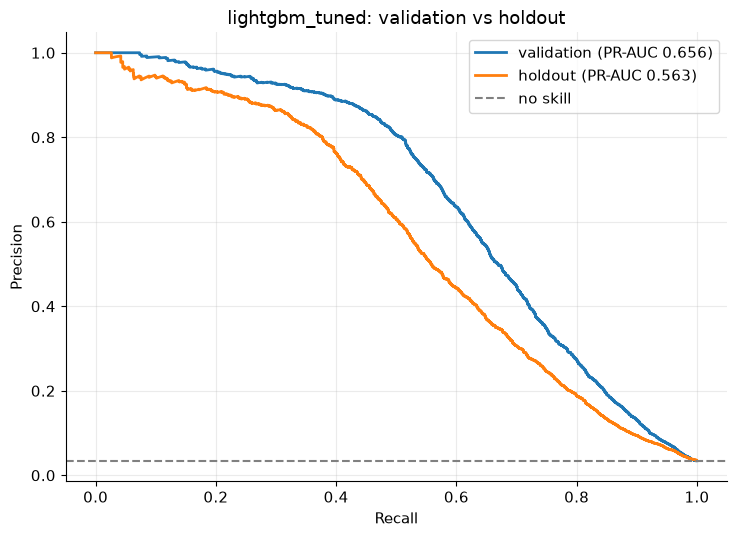

In [21]:
# Same slices on holdout (descriptive only: nothing gets tuned from this)
masks_h = {"all holdout": np.ones(len(y_h), dtype=bool)}
if "b_hist_count" in X_h:
    masks_h["cold start (card has no history)"] = (X_h["b_hist_count"] == 0).to_numpy()
    masks_h["warm (card has history)"] = (X_h["b_hist_count"] > 0).to_numpy()
if "has_identity" in X_h:
    masks_h["no identity data"] = (X_h["has_identity"] == 0).to_numpy()
    masks_h["has identity data"] = (X_h["has_identity"] == 1).to_numpy()
display(ev.slice_report(y_h, raw_h, masks_h, FPR_TARGET))

# Precision-recall curve: validation vs holdout for the final model
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for label, y_, s_ in [("validation", y_va, raw_va), ("holdout", y_h, raw_h)]:
    prec, rec, _ = precision_recall_curve(y_, s_)
    ax.plot(rec, prec, lw=2, label=f"{label} (PR-AUC {average_precision_score(y_, s_):.3f})")
ax.axhline(y_h.mean(), ls="--", color="gray", label="no skill")
ax.set(xlabel="Recall", ylabel="Precision", title=f"{FINAL_NAME}: validation vs holdout")
ax.legend()
plt.tight_layout()
save_fig("04_pr_validation_vs_holdout")
plt.show()

## 10. Save artifacts and hand off  *(tracker 3.9)*

| File | Used by |
|---|---|
| `ml/artifacts/model.xgb.json` or `model.lgb.txt` | FastAPI (loaded once at startup), SHAP in Phase 4 |
| `ml/artifacts/calibrator.json` | FastAPI: raw score → probability → 0 to 100 risk score (pure JSON, `np.interp` / sigmoid) |
| `ml/artifacts/model_meta.json` | Version string, model type, params, tree count, feature-order hash, metrics |
| `ml/artifacts/best_params.json` | `ml/training/train.py` (reproducible retrain) |
| `data/processed/val_predictions.parquet`, `holdout_predictions.parquet` | **Phase 4** cost model and threshold search (id, amount, label, raw + calibrated score) |

In [22]:
metrics_out = {
    "validation": val_final,
    "holdout": hold[FINAL_NAME],
    "baseline_logreg": {"validation": results["logreg"], "holdout": hold["logreg"]},
    "threshold_from_validation_at_1pct_fpr_raw_score": thr_final,
    "calibration_table_later_half_validation": cal_table.reset_index().to_dict(orient="records"),
}
info = T.save_artifacts(ARTIFACTS_DIR, FINAL_TYPE, final_model, calibrator,
                        params={**FAST_OVR, **FINAL_PARAMS}, n_trees=FINAL_TREES, features=FEATURES,
                        metrics=metrics_out,
                        extra={"selected_variant": FINAL_NAME, "split_cutoffs": schema.get("split_cutoffs"),
                                "fast_mode": FAST})
json.dump({"model": FINAL_TYPE, "params": {**FAST_OVR, **FINAL_PARAMS}}, open(ARTIFACTS_DIR / "best_params.json", "w"), indent=2, default=float)
print("Saved model version:", info["version"])

# Predictions for Phase 4 (amount is needed for the money-based cost model)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
def pred_frame(meta_, X_, raw_, cal_):
    return pd.DataFrame({"TransactionID": meta_["TransactionID"].to_numpy(), "TransactionDT": meta_["TransactionDT"].to_numpy(),
                         "isFraud": meta_["isFraud"].to_numpy(), "TransactionAmt": X_["TransactionAmt"].to_numpy() if "TransactionAmt" in X_ else np.nan,
                         "raw_score": raw_, "calibrated_prob": cal_})
for fname, frame in [("val_predictions", pred_frame(meta_va, X_va, raw_va, cal_va)),
                     ("holdout_predictions", pred_frame(meta_h, X_h, raw_h, cal_h))]:
    try:
        frame.to_parquet(PROCESSED_DIR / f"{fname}.parquet", index=False)
    except ImportError:
        frame.to_pickle(PROCESSED_DIR / f"{fname}.pkl")
print("Saved validation + holdout predictions to", PROCESSED_DIR.resolve())

# Round-trip check: reload from disk and make sure the saved pair reproduces the in-memory scores
cal_reload = T.Calibrator.from_json(ARTIFACTS_DIR / "calibrator.json")
np.testing.assert_allclose(cal_reload.predict(raw_va), cal_va, rtol=1e-9)
if FINAL_TYPE == "xgboost":
    import xgboost as xgb
    reloaded = xgb.XGBClassifier()
    reloaded.load_model(str(ARTIFACTS_DIR / info["model_file"]))
    chk = reloaded.predict_proba(X_va.head(2000))[:, 1]
else:
    import lightgbm as lgb
    chk = lgb.Booster(model_file=str(ARTIFACTS_DIR / info["model_file"])).predict(X_va.head(2000))
np.testing.assert_allclose(chk, raw_va[:2000], rtol=1e-4, atol=1e-6)
print("PASS: reloaded model + calibrator reproduce the in-memory validation scores.")

Saved model version: lightgbm-20261009-082818-e67cbcb5
Saved validation + holdout predictions to C:\VS CODE\PROJECTS\FraudShield AI\data\processed
PASS: reloaded model + calibrator reproduce the in-memory validation scores.


### Tracker numbers (copy into the tracker and README)

In [23]:
h, v = hold[FINAL_NAME], val_final
b = hold["logreg"]
print("| Metric | Baseline (LogReg) | Final model | Notes |")
print("|---|---|---|---|")
print(f"| PR-AUC (holdout)  | {b['pr_auc']:.3f} | {h['pr_auc']:.3f} | validation {v['pr_auc']:.3f} |")
print(f"| ROC-AUC (holdout) | {b['roc_auc']:.3f} | {h['roc_auc']:.3f} | validation {v['roc_auc']:.3f} |")
print(f"| Recall @ 1% FPR (oracle)              | {b['recall_at_fpr']:.3f} | {h['recall_at_fpr']:.3f} | best achievable on holdout |")
print(f"| Recall @ validation threshold         | {b['recall_at_thr']:.3f} | {h['recall_at_thr']:.3f} | actual FPR {h['fpr_at_thr']:.2%} |")
print(f"| Precision @ validation threshold      | {b['precision_at_thr']:.3f} | {h['precision_at_thr']:.3f} | flags {h['flagged_share_at_thr']:.2%} of traffic |")
print(f"\nBest model: {FINAL_NAME} | calibration: {BEST_CAL} | version: {info['version']}")

| Metric | Baseline (LogReg) | Final model | Notes |
|---|---|---|---|
| PR-AUC (holdout)  | 0.374 | 0.563 | validation 0.656 |
| ROC-AUC (holdout) | 0.861 | 0.908 | validation 0.930 |
| Recall @ 1% FPR (oracle)              | 0.319 | 0.483 | best achievable on holdout |
| Recall @ validation threshold         | 0.379 | 0.526 | actual FPR 1.50% |
| Precision @ validation threshold      | 0.417 | 0.558 | flags 3.28% of traffic |

Best model: lightgbm_tuned | calibration: sigmoid | version: lightgbm-20261009-082818-e67cbcb5


## 11. Key findings

> ✍️ **Fill this in yourself after running the notebook.** Business language, always with a number. Delete the prompts when done.

1. **Model comparison:** XGBoost PR-AUC ___ vs LightGBM ___ vs LogReg ___ on validation. Winner: ___ because ___ (quality / speed).
2. **Tuning:** Optuna moved PR-AUC from ___ to ___ (or: did not help, so we kept the defaults).
3. **Operating point:** at a 1% false-positive budget the model catches ___% of fraud with ___% precision on the holdout (threshold fixed on validation; actual FPR ___%).
4. **Cold start:** cards with no history get recall ___% vs ___% for cards with history, so the demo form will ___.
5. **Drift risk:** simulating unseen `id_31` values changed PR-AUC by ___, so ___.
6. **Calibration:** raw scores averaged ___ vs a true rate of ___; after `___` calibration they match (ECE ___).
7. **Top fraud drivers (gain):** ___, ___, ___. Do the engineered card-history features appear? ___

### Tracker updates (Phase 3)

| # | Task | Status |
|---|---|---|
| 3.1 | Logistic Regression baseline | ✅ |
| 3.2 | XGBoost | ✅ |
| 3.3 | LightGBM | ✅ |
| 3.4 | Optuna tuning (time-aware, inside train) | ✅ |
| 3.5 | PR-AUC / ROC-AUC / recall @ 1% FPR | ✅ |
| 3.6 | PR + ROC curves | ✅ |
| 3.7 | Calibration | ✅ |
| 3.8 | Final holdout evaluation (run once) | ✅ |
| 3.9 | Model + calibrator + metadata saved | ✅ |

### Handoff to Phase 4 (thresholds & explainability)
- Load `data/processed/val_predictions.parquet` (has `TransactionAmt`, `isFraud`, `raw_score`, `calibrated_prob`). Pick the two thresholds there, then apply them to `holdout_predictions.parquet` for the "savings vs approve-everything" number.
- The calibrator was fit on validation, so thresholds searched on *calibrated validation scores* are slightly optimistic. Searching on `raw_score` quantiles avoids that; either is fine if you state it.
- The risk score shown to users is `round(100 × calibrated_prob)`: a score of 87 means about an 87% fraud probability, so most traffic will sit near 0 to 5. Band thresholds should be chosen on the cost model, not on "score > 50".
- SHAP: use `shap.TreeExplainer` on the saved booster. Group the many `V*` columns when mapping to readable reasons.
- `new_addr_flag` is constant (always 0 by construction, because address is part of the card key). Safe to drop in a later schema version; keeping it for now preserves feature-order parity with the saved schema.
- Serving: the model expects exactly `feature_schema.json["feature_order"]`; `model_meta.json` stores its SHA-256 so the API can refuse to start on a mismatch.

---
**Next:** Phase 4 — `04_Thresholds_and_Explainability.ipynb`.